<div style="color:#3c4d5a; background-color:#fff; border-top:7px solid #42A5F5; border-bottom:7px solid #42A5F5; padding:16px 8px; text-align:center; text-transform:uppercase;">
<h2 style="color:inherit; border:0; margin:8px 0;">UNIVERSIDAD POLITÉCNICA SALESIANA</h2>
<h3 style="color:inherit; margin:8px 0;">Carrera de Computación · Aprendizaje Automático</h3>
<h1 style="color:inherit; margin:14px 0;">Práctica 2: Predicción de demanda con SVM</h1>
</div>

<p><b>Desarrollado por:</b> Daniel Guanga , Alex Guamán y Cinthya Ramón<br>
<b>Docente:</b> Ing. Remigio Hurtado · <b>Fecha:</b> noviembre 2026</p>


**Dataset:** Escenario sintético de La Favorita: 10 productos, 365 días (01/10/2025 – 30/09/2026), 3.650 ventas.
- `sales_history.csv`: producto, fecha, `cantidad_vendida` (demanda) y `stock_en_momento` (stock al inicio del día).
- `inventory.csv`: categoría y unidad de cada producto.

**Objetivo:** predecir la demanda diaria con una **SVR** (SVM para regresión) y compararla con la LSTM de la Práctica 1 (RMSE 4,40 en septiembre de 2026).

<div id="contenido" style="color:#37475a; background-color:#fff; border-bottom:7px solid orange; width:100%; margin:24px 0 15px; padding-bottom:2px;"><h2 style="color:inherit;">Contenido</h2></div>

- [Parte 1: Datos y SVR](#parte1)
  - [1.1 Variables de entrada](#variables-entrada)
  - [1.2 División por fechas](#division-fechas)
  - [1.3 Comparación de kernels](#comparacion-kernels)
  - [1.4 Efecto de C](#regularizacion-c)
  - [1.5 Efecto de épsilon](#efecto-epsilon)
  - [1.6 Evaluación en prueba](#evaluacion-prueba)
- [Parte 2: Fine-tuning con MLflow](#parte2)
  - [2.1 Configuración de MLflow](#preparacion-parte2)
  - [2.2 Modelo base](#modelo-base)
  - [2.3 GridSearch y RandomSearch](#experimentos-mlflow)
  - [2.4 GridSearch frente a RandomSearch](#grid-frente-random)
  - [2.5 Registro del mejor modelo](#registro-modelo)
  - [2.6 Del modelo base al mejor modelo](#base-vs-mejor)
  - [2.7 Ejemplos para el cliente](#ejemplos-cliente)
- [Conclusiones](#conclusiones)
- [Referencias](#referencias)

<div id="parte1" style="color:#37475a; background-color:#fff; border-bottom:7px solid orange; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h2 style="color:inherit;">Parte 1: Datos y SVR</h2></div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error

FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

ventas = pd.read_csv("data/sales_history.csv", dtype={"product_id": str}, parse_dates=["fecha_venta"])
inventario = pd.read_csv("data/inventory.csv", dtype={"product_id": str})
ventas = ventas.sort_values(["product_id", "fecha_venta"]).reset_index(drop=True)
ventas["stock_cierre"] = ventas["stock_en_momento"] - ventas["cantidad_vendida"]
print(ventas.shape)
ventas.head()

(3650, 6)


,product_id,nombre,fecha_venta,cantidad_vendida,stock_en_momento,stock_cierre
0,103665,Pan de Molde Blanco,2025-10-01,34.0,140.0,106.0
1,103665,Pan de Molde Blanco,2025-10-02,32.0,106.0,74.0
2,103665,Pan de Molde Blanco,2025-10-03,39.0,74.0,35.0
3,103665,Pan de Molde Blanco,2025-10-04,47.0,140.0,93.0
4,103665,Pan de Molde Blanco,2025-10-05,40.0,93.0,53.0


<div id="variables-entrada" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.1 Variables de entrada</h3></div>

La SVM no recuerda el orden del tiempo como la LSTM, por eso cada fila debe traer su propio contexto: la **fecha como timestamp**, el calendario y los rezagos de la venta y del stock. Los rezagos solo usan días anteriores, así no hay fuga.

In [2]:
FERIADOS = pd.DatetimeIndex(list(holidays.EC(years=[2025, 2026]).keys()))
VISPERAS = FERIADOS - pd.Timedelta(days=1)

def crear_variables(df):
    X = pd.DataFrame(index=df.index)
    f = df["fecha_venta"]
    X["timestamp"] = f.astype("datetime64[s]").astype("int64")
    X["dia_semana"] = f.dt.day_of_week
    X["mes"] = f.dt.month
    X["fin_de_semana"] = (f.dt.day_of_week >= 5).astype(int)
    X["es_feriado"] = f.isin(FERIADOS).astype(int)
    X["vispera_feriado"] = f.isin(VISPERAS).astype(int)
    X["dia_pago"] = (f.dt.day.between(14, 16) | (f.dt.day >= f.dt.days_in_month - 2)).astype(int)
    X["navidad"] = ((f.dt.month == 12) & (f.dt.day >= 15)).astype(int)
    g = df.groupby("product_id")
    X["venta_ayer"] = g["cantidad_vendida"].shift(1)
    X["venta_hace_7"] = g["cantidad_vendida"].shift(7)
    X["media_7"] = g["cantidad_vendida"].transform(lambda s: s.shift(1).rolling(7).mean())
    X["stock_ayer"] = g["stock_cierre"].shift(1)
    return X.join(pd.get_dummies(df["product_id"], prefix="prod", dtype=int))

X = crear_variables(ventas)
y = ventas["cantidad_vendida"]
validas = X.notna().all(axis=1)
X, y, datos = X[validas], y[validas], ventas[validas]
print(X.shape)
X.head(3)

(3580, 22)


C:\Users\kenny\AppData\Local\Temp\ipykernel_6724\3995922698.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  VISPERAS = FERIADOS - pd.Timedelta(days=1)


,timestamp,dia_semana,mes,fin_de_semana,es_feriado,vispera_feriado,dia_pago,navidad,venta_ayer,venta_hace_7,...,prod_103665,prod_105574,prod_108634,prod_108701,prod_114674,prod_119024,prod_121528,prod_123601,prod_126938,prod_135432
7,1759881600,2,10,0,0,1,0,0,34.0,34.0,...,1,0,0,0,0,0,0,0,0,0
8,1759968000,3,10,0,1,1,0,0,37.0,32.0,...,1,0,0,0,0,0,0,0,0,0
9,1760054400,4,10,0,1,0,0,0,42.0,39.0,...,1,0,0,0,0,0,0,0,0,0


<div id="division-fechas" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.2 División por fechas</h3></div>

Igual que en la Práctica 1: **validación** del 2 al 31 de agosto y **prueba** en septiembre de 2026 (300 filas cada una). Sin barajar, porque es una serie de tiempo.

In [3]:
fecha = datos["fecha_venta"]
tr = fecha < "2026-08-02"
va = (fecha >= "2026-08-02") & (fecha < "2026-09-01")
te = fecha >= "2026-09-01"
X_tr, y_tr, X_va, y_va, X_te, y_te = X[tr], y[tr], X[va], y[va], X[te], y[te]
print(f"train {len(X_tr)} | val {len(X_va)} | test {len(X_te)}")

def rmse(real, pred):
    return np.sqrt(mean_squared_error(real, pred))

train 2980 | val 300 | test 300


<div id="comparacion-kernels" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.3 Comparación de kernels</h3></div>

La SVM depende de la escala de las variables, por eso va en un `Pipeline` con `StandardScaler` (se ajusta solo con train). Se prueban los tres kernels con los mismos C y épsilon.

,RMSE train,RMSE val
kernel,,
lineal,3.88,4.24
RBF,2.71,3.58
polinomial (grado 3),2.66,3.63


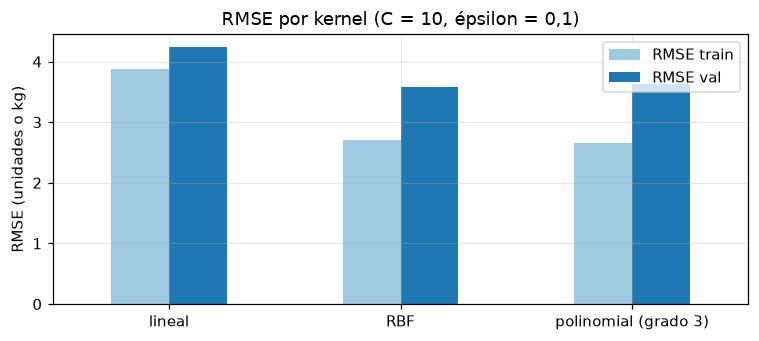

In [4]:
kernels = {"lineal": SVR(kernel="linear", C=10),
           "RBF": SVR(kernel="rbf", C=10),
           "polinomial (grado 3)": SVR(kernel="poly", degree=3, C=10)}
filas = []
for nombre, svr in kernels.items():
    modelo = make_pipeline(StandardScaler(), svr).fit(X_tr, y_tr)
    filas.append({"kernel": nombre,
                  "RMSE train": rmse(y_tr, modelo.predict(X_tr)),
                  "RMSE val": rmse(y_va, modelo.predict(X_va))})
res_kernel = pd.DataFrame(filas).set_index("kernel").round(2)
display(res_kernel)

res_kernel.plot(kind="bar", figsize=(7, 3.2), color=["#9ecae1", "#1f77b4"], rot=0)
plt.title("RMSE por kernel (C = 10, épsilon = 0,1)"); plt.ylabel("RMSE (unidades o kg)"); plt.xlabel("")
plt.tight_layout(); plt.savefig(FIG / "01_kernels.png", dpi=200); plt.show()

**Resultado:** RBF (3,58) y polinomial (3,63) superan al lineal (4,24) en validación, porque la demanda no depende de forma lineal del calendario y los rezagos. Se sigue con **RBF**, que además tiene menos diferencia entre train y validación que el polinomial.

<div id="regularizacion-c" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.4 Efecto de C (regularización)</h3></div>

C es la penalización del error de entrenamiento: con C pequeño el modelo es rígido (subajuste) y con C grande se pega a train (sobreajuste).

,C,train,val
0,0.1,6.80,8.02
1,0.3,5.23,6.20
2,1.0,4.02,4.95
3,3.0,3.18,4.02
4,10.0,2.71,3.58
5,30.0,2.49,3.60
6,100.0,2.31,3.74
7,300.0,2.17,4.03
8,1000.0,1.98,4.45


Mejor C según validación: 10.0


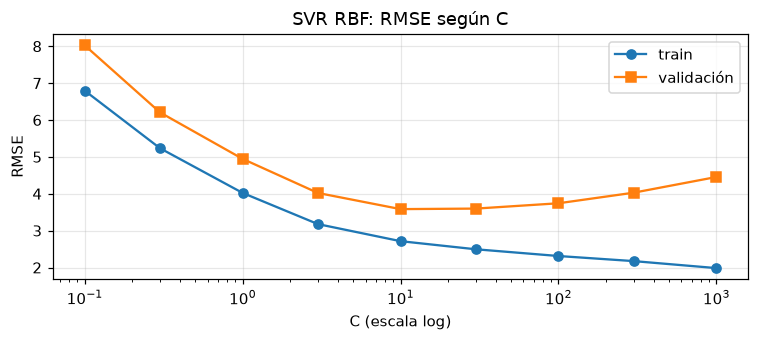

In [5]:
valores_C = [0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]
filas = []
for C in valores_C:
    modelo = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=C)).fit(X_tr, y_tr)
    filas.append({"C": C, "train": rmse(y_tr, modelo.predict(X_tr)), "val": rmse(y_va, modelo.predict(X_va))})
curva_C = pd.DataFrame(filas)
display(curva_C.round(2))
MEJOR_C = curva_C.loc[curva_C["val"].idxmin(), "C"]
print("Mejor C según validación:", MEJOR_C)

plt.figure(figsize=(7, 3.2))
plt.semilogx(curva_C["C"], curva_C["train"], "o-", label="train")
plt.semilogx(curva_C["C"], curva_C["val"], "s-", label="validación")
plt.title("SVR RBF: RMSE según C"); plt.xlabel("C (escala log)"); plt.ylabel("RMSE"); plt.legend()
plt.tight_layout(); plt.savefig(FIG / "02_curva_C.png", dpi=200); plt.show()

**Resultado:** con C = 0,1 el modelo subajusta (RMSE val 8,02). El mínimo de validación está en **C = 10** (3,58). Desde ahí el error de train sigue bajando (hasta 1,98) pero el de validación sube (4,45 con C = 1000): eso es **sobreajuste**.

<div id="efecto-epsilon" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.5 Efecto de épsilon</h3></div>

Épsilon es el ancho del "tubo": los errores menores a épsilon no se penalizan. Un tubo más ancho deja menos vectores de soporte y un modelo más simple.

,epsilon,RMSE val,% vectores de soporte
0,0.1,3.58,95.87
1,0.5,3.60,80.54
2,1.0,3.61,65.34
3,2.0,3.67,41.74
4,4.0,4.10,18.59
5,8.0,5.48,5.77


Mejor épsilon según validación: 0.1


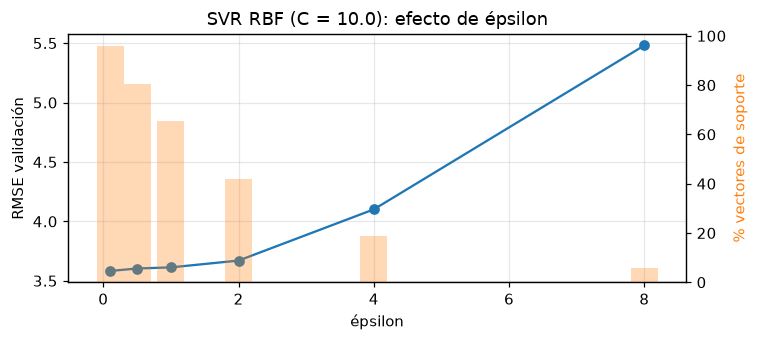

In [6]:
filas = []
for eps in [0.1, 0.5, 1, 2, 4, 8]:
    modelo = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=MEJOR_C, epsilon=eps)).fit(X_tr, y_tr)
    filas.append({"epsilon": eps, "RMSE val": rmse(y_va, modelo.predict(X_va)),
                  "% vectores de soporte": 100 * len(modelo[-1].support_) / len(X_tr)})
curva_eps = pd.DataFrame(filas)
display(curva_eps.round(2))
MEJOR_EPS = curva_eps.loc[curva_eps["RMSE val"].idxmin(), "epsilon"]
print("Mejor épsilon según validación:", MEJOR_EPS)

fig, ax1 = plt.subplots(figsize=(7, 3.2))
ax1.plot(curva_eps["epsilon"], curva_eps["RMSE val"], "o-", color="#1f77b4")
ax1.set(xlabel="épsilon", ylabel="RMSE validación", title=f"SVR RBF (C = {MEJOR_C}): efecto de épsilon")
ax2 = ax1.twinx()
ax2.bar(curva_eps["epsilon"], curva_eps["% vectores de soporte"], width=0.4, alpha=0.3, color="#ff7f0e")
ax2.set_ylabel("% vectores de soporte", color="#ff7f0e"); ax2.grid(False)
plt.tight_layout(); plt.savefig(FIG / "03_epsilon.png", dpi=200); plt.show()

**Resultado:** el mejor épsilon es **0,1** (RMSE val 3,58), aunque usa el 96 % de las filas como vectores de soporte. Con épsilon = 2 el error casi no cambia (3,67) y solo usa el 42 %: un modelo más liviano por muy poco error extra.

<div id="evaluacion-prueba" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">1.6 Evaluación en prueba</h3></div>

Se entrena el mejor SVR (elegido con validación) con train + validación y se mide en septiembre. Se compara con dos líneas base y con la LSTM de la Práctica 1.

In [7]:
final = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=MEJOR_C, epsilon=MEJOR_EPS))
final.fit(pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va]))
pred = np.clip(final.predict(X_te), 0, None)

comparacion = pd.DataFrame([
    {"modelo": "Base: venta de ayer", "RMSE": rmse(y_te, X_te["venta_ayer"]), "MAE": mean_absolute_error(y_te, X_te["venta_ayer"])},
    {"modelo": "Base: mismo día de la semana anterior", "RMSE": rmse(y_te, X_te["venta_hace_7"]), "MAE": mean_absolute_error(y_te, X_te["venta_hace_7"])},
    {"modelo": "LSTM (Práctica 1)", "RMSE": 4.40, "MAE": 3.10},
    {"modelo": f"SVR RBF (C={MEJOR_C}, ε={MEJOR_EPS})", "RMSE": rmse(y_te, pred), "MAE": mean_absolute_error(y_te, pred)},
]).set_index("modelo").round(2)
display(comparacion)

stock_real = datos.loc[te, "stock_cierre"]
stock_pred = (datos.loc[te, "stock_en_momento"] - pred).clip(lower=0)
print(f"RMSE del stock al cierre calculado con la SVR: {rmse(stock_real, stock_pred):.2f}")

,RMSE,MAE
modelo,,
Base: venta de ayer,6.47,4.51
Base: mismo día de la semana anterior,4.39,3.29
LSTM (Práctica 1),4.40,3.10
"SVR RBF (C=10.0, ε=0.1)",3.21,2.29


RMSE del stock al cierre calculado con la SVR: 3.21


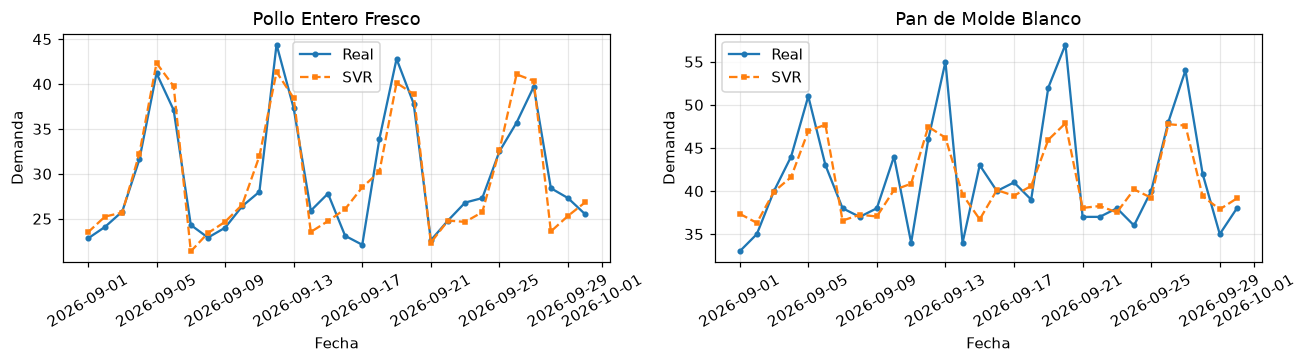

In [8]:
prueba = datos.loc[te, ["product_id", "nombre", "fecha_venta", "cantidad_vendida"]].assign(pred=pred)
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, cod in zip(ejes, ["114674", "103665"]):
    g = prueba[prueba["product_id"] == cod]
    ax.plot(g["fecha_venta"], g["cantidad_vendida"], "o-", ms=3, label="Real")
    ax.plot(g["fecha_venta"], g["pred"], "s--", ms=3, label="SVR")
    ax.set(title=g["nombre"].iloc[0], xlabel="Fecha", ylabel="Demanda"); ax.legend()
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG / "04_prediccion_vs_real.png", dpi=200); plt.show()

<div id="parte2" style="color:#37475a; background-color:#fff; border-bottom:7px solid orange; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h2 style="color:inherit;">Parte 2: Fine-tuning con MLflow</h2></div>

Se parte de un modelo base sencillo y se mejora ajustando kernel, C, gamma y épsilon con GridSearch y RandomSearch. Cada prueba queda registrada en MLflow, en una base SQLite local (`mlflow.db`) que no necesita cuenta.

<div id="preparacion-parte2" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.1 Configuración de MLflow</h3></div>

`PredefinedSplit` mantiene la validación de agosto durante las búsquedas, y el escalador se ajusta dentro del pipeline solo con train. Gamma no aplica al kernel lineal.

In [9]:
import json
import os
from time import perf_counter
import logging
import warnings
os.environ["MLFLOW_DISABLE_TELEMETRY"] = "true"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import mlflow
import mlflow.sklearn
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, PredefinedSplit
logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

TRACKING_URI = "sqlite:///" + (Path.cwd() / "mlflow.db").as_posix()
EXPERIMENTO = "practica2_svr"
MODELO_REGISTRADO = "svr_demanda"
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_registry_uri(TRACKING_URI)
cliente = MlflowClient()
experimento = cliente.get_experiment_by_name(EXPERIMENTO)
if experimento is None:
    experimento_id = cliente.create_experiment(
        EXPERIMENTO, artifact_location=(Path.cwd() / "mlartifacts").as_uri())
else:
    experimento_id = experimento.experiment_id
mlflow.set_experiment(EXPERIMENTO)

X_busqueda = pd.concat([X_tr, X_va])
y_busqueda = pd.concat([y_tr, y_va])
division = PredefinedSplit(np.r_[np.full(len(X_tr), -1), np.zeros(len(X_va))].astype(int))
espacio = [
    {"svr__kernel": ["linear"], "svr__C": [1, 10, 100], "svr__epsilon": [0.1, 1]},
    {"svr__kernel": ["rbf", "poly"], "svr__C": [1, 10, 100],
     "svr__gamma": ["scale", 0.01, 0.1], "svr__epsilon": [0.1, 1]},
]
opciones = dict(estimator=make_pipeline(StandardScaler(), SVR()), cv=division,
                scoring="neg_root_mean_squared_error", return_train_score=True,
                refit=False, n_jobs=1, error_score="raise")
busquedas = {
    "GridSearch": GridSearchCV(param_grid=espacio, **opciones),
    "RandomSearch": RandomizedSearchCV(param_distributions=espacio, n_iter=20,
                                        random_state=42, **opciones),
}

C:\Users\kenny\OneDrive\Documents\icc-aa-practica2\icc-aa-practica2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<div id="modelo-base" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.2 Modelo base</h3></div>

El punto de partida es un SVR **lineal con los valores por defecto** (C = 1, ε = 0,1). También se registra el ajuste manual de la Parte 1 (RBF, C = 10) para tener las tres etapas en el historial de MLflow.

In [10]:
etapas = {"base": SVR(kernel="linear"),
          "ajuste_manual": SVR(kernel="rbf", C=MEJOR_C, epsilon=MEJOR_EPS)}
modelos_etapa = {}
for nombre, svr in etapas.items():
    modelo = make_pipeline(StandardScaler(), svr).fit(X_tr, y_tr)
    modelos_etapa[nombre] = modelo
    with mlflow.start_run(run_name=nombre):
        mlflow.set_tags({"parte": "2", "etapa": nombre})
        mlflow.log_params({"kernel": svr.kernel, "C": svr.C, "epsilon": svr.epsilon, "gamma": svr.gamma})
        mlflow.log_metrics({"rmse_train": rmse(y_tr, modelo.predict(X_tr)),
                            "rmse_val": rmse(y_va, modelo.predict(X_va))})
    print(f"{nombre}: RMSE train {rmse(y_tr, modelo.predict(X_tr)):.3f} | RMSE val {rmse(y_va, modelo.predict(X_va)):.3f}")

base: RMSE train 3.882 | RMSE val 4.243


ajuste_manual: RMSE train 2.714 | RMSE val 3.583


<div id="experimentos-mlflow" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.3 GridSearch y RandomSearch</h3></div>

GridSearch prueba las 42 combinaciones del espacio y RandomSearch toma 20 al azar (semilla 42). Cada búsqueda es una ejecución principal en MLflow y cada candidato una ejecución hija, con sus parámetros, RMSE de train y validación, tiempo y figura.

In [11]:
filas_experimentos, filas_resumen, runs_busquedas = [], [], {}
for nombre, busqueda in busquedas.items():
    with mlflow.start_run(run_name=nombre) as ejecucion:
        runs_busquedas[nombre] = ejecucion.info.run_id
        mlflow.set_tags({"parte": "2", "busqueda": nombre})
        inicio = perf_counter()
        busqueda.fit(X_busqueda, y_busqueda)
        duracion = perf_counter() - inicio
        cv = busqueda.cv_results_
        for i, parametros_svr in enumerate(cv["params"]):
            parametros = {k.removeprefix("svr__"): v for k, v in parametros_svr.items()}
            parametros.setdefault("gamma", "no_aplica")
            error_train = float(-cv["mean_train_score"][i])
            error_val = float(-cv["mean_test_score"][i])
            with mlflow.start_run(run_name=f"{nombre}_{i + 1:02d}", nested=True) as candidato:
                mlflow.log_params(parametros)
                mlflow.log_metrics({"rmse_train": error_train, "rmse_val": error_val,
                                    "tiempo_fit_s": float(cv["mean_fit_time"][i])})
                fig, ax = plt.subplots(figsize=(4, 2.8))
                ax.bar(["Train", "Validación"], [error_train, error_val], color=["#9ecae1", "#1f77b4"])
                ax.set(title=f"{nombre}: candidato {i + 1}", ylabel="RMSE de demanda")
                fig.tight_layout()
                mlflow.log_figure(fig, "rmse.png")
                plt.close(fig)
                filas_experimentos.append({"busqueda": nombre, "candidato": i + 1,
                    **parametros, "rmse_train": error_train, "rmse_val": error_val,
                    "tiempo_fit_s": float(cv["mean_fit_time"][i]), "run_id": candidato.info.run_id})
        mejor = busqueda.best_index_
        mlflow.log_metrics({"rmse_train": float(-cv["mean_train_score"][mejor]),
                            "rmse_val": float(-busqueda.best_score_), "tiempo_s": duracion,
                            "candidatos": len(cv["params"])})
        filas_resumen.append({"busqueda": nombre, "candidatos": len(cv["params"]),
            "rmse_train": float(-cv["mean_train_score"][mejor]),
            "rmse_val": float(-busqueda.best_score_), "tiempo_s": duracion})
        print(f"{nombre}: {len(cv['params'])} candidatos; RMSE val = {-busqueda.best_score_:.3f}; {duracion:.2f} s")
resultados = pd.DataFrame(filas_experimentos)
resumen_busquedas = pd.DataFrame(filas_resumen).set_index("busqueda")
display(resultados.sort_values("rmse_val").head(10).round(4))

GridSearch: 42 candidatos; RMSE val = 3.290; 52.51 s


RandomSearch: 20 candidatos; RMSE val = 3.506; 23.88 s


,busqueda,candidato,C,epsilon,kernel,gamma,rmse_train,rmse_val,tiempo_fit_s,run_id
38,GridSearch,39,100,1.0,rbf,0.01,2.7862,3.2897,0.2004,d386fd0c1366421db7c0311a45a50f96
32,GridSearch,33,100,0.1,rbf,0.01,2.7980,3.3048,0.2780,12662ad6f3804d92b4c73a06d5df07e0
20,GridSearch,21,10,0.1,rbf,0.01,3.1226,3.4722,0.2027,03a8e4ffd61f4e79a1393281cb40b0cf
26,GridSearch,27,10,1.0,rbf,0.01,3.1365,3.5065,0.1363,435e6d8810c046ad93777314b1e70ee0
45,RandomSearch,4,10,1.0,rbf,0.01,3.1365,3.5065,0.1407,f776a7e18fe3453cac1118480ced05af
42,RandomSearch,1,10,1.0,poly,scale,2.6441,3.5641,0.1854,1c6c9552eb1a4e86a14cc8cd8ff8fd64
25,GridSearch,26,10,1.0,poly,scale,2.6441,3.5641,0.1856,58c910724d074060a0b7aab8f33c8876
17,GridSearch,18,1,1.0,poly,0.1,2.6341,3.5675,0.1853,6fe314470461496a89a0991e59673253
54,RandomSearch,13,1,1.0,poly,0.1,2.6341,3.5675,0.1865,f05620d64d7d45328f36c16ef59d8133
18,GridSearch,19,10,0.1,rbf,scale,2.7138,3.5829,0.2196,a48fd9d478ef40e8bab01e5d739bf169


<div id="grid-frente-random" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.4 GridSearch frente a RandomSearch</h3></div>

Mejor RMSE de agosto y tiempo total de cada búsqueda. Los resultados también quedan en `resultados/` como CSV.

,candidatos,rmse_train,rmse_val,tiempo_s
busqueda,,,,
GridSearch,42,2.7862,3.2897,52.5103
RandomSearch,20,3.1365,3.5065,23.8784


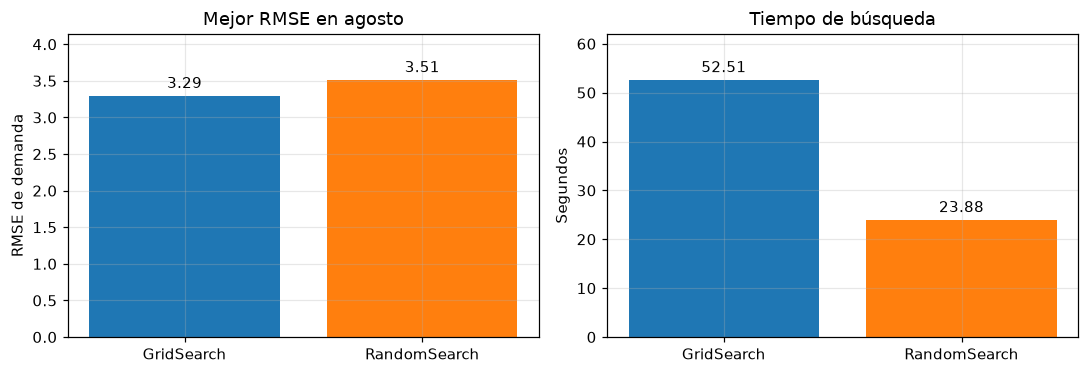

In [12]:
SALIDA = Path("resultados")
SALIDA.mkdir(exist_ok=True)
resultados.to_csv(SALIDA / "parte2_experimentos.csv", index=False)
resumen_busquedas.to_csv(SALIDA / "parte2_comparacion.csv")
display(resumen_busquedas.round(4))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, columna, titulo, unidad in zip(axes, ["rmse_val", "tiempo_s"],
        ["Mejor RMSE en agosto", "Tiempo de búsqueda"], ["RMSE de demanda", "Segundos"]):
    barras = ax.bar(resumen_busquedas.index, resumen_busquedas[columna], color=["#1f77b4", "#ff7f0e"])
    ax.set(title=titulo, ylabel=unidad)
    ax.bar_label(barras, fmt="%.2f", padding=3)
    ax.margins(y=0.18)
fig.tight_layout()
fig.savefig(FIG / "05_grid_vs_random.png", dpi=200)
for run_id in runs_busquedas.values():
    with mlflow.start_run(run_id=run_id):
        mlflow.log_figure(fig, "grid_vs_random.png")
        mlflow.log_artifact(str(SALIDA / "parte2_experimentos.csv"))
        mlflow.log_artifact(str(SALIDA / "parte2_comparacion.csv"))
plt.show()

<div id="registro-modelo" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.5 Registro del mejor modelo</h3></div>

Se elige la configuración con menor RMSE de agosto, se reentrena con train + agosto y se evalúa una vez en septiembre. El pipeline (StandardScaler + SVR) queda registrado como `svr_demanda` con número de versión.

In [13]:
ganador = resumen_busquedas.sort_values(["rmse_val", "tiempo_s"]).index[0]
seleccionada = busquedas[ganador]
mejor_modelo = clone(seleccionada.estimator).set_params(**seleccionada.best_params_)
mejor_modelo.fit(X_busqueda, y_busqueda)
pred_parte2 = mejor_modelo.predict(X_te)
rmse_test_parte2 = float(rmse(y_te, pred_parte2))
with mlflow.start_run(run_name="mejor_modelo") as ejecucion_final:
    mlflow.set_tags({"parte": "2", "busqueda_origen": ganador})
    mlflow.log_params({k.removeprefix("svr__"): v for k, v in seleccionada.best_params_.items()})
    mlflow.log_metrics({"rmse_val_seleccion": float(-seleccionada.best_score_),
                        "rmse_test": rmse_test_parte2,
                        "rmse_train_final": float(rmse(y_busqueda, mejor_modelo.predict(X_busqueda)))})
    firma = infer_signature(X_tr, mejor_modelo.predict(X_tr))
    modelo_guardado = mlflow.sklearn.log_model(mejor_modelo, name="modelo",
                                               signature=firma, input_example=X_tr.head(2))
    version_registrada = mlflow.register_model(modelo_guardado.model_uri, MODELO_REGISTRADO)
    modelo_uri = f"models:/{MODELO_REGISTRADO}/{version_registrada.version}"
    entrega_parte2 = {"nombre": MODELO_REGISTRADO, "version": version_registrada.version,
        "modelo_uri": modelo_uri, "tracking_uri": TRACKING_URI,
        "run_id": ejecucion_final.info.run_id, "busqueda": ganador,
        "parametros": seleccionada.best_params_, "columnas": list(X_tr.columns),
        "objetivo": "cantidad_vendida", "rmse_val": float(-seleccionada.best_score_),
        "rmse_test": rmse_test_parte2}
    (SALIDA / "parte2_modelo.json").write_text(
        json.dumps(entrega_parte2, ensure_ascii=False, indent=2), encoding="utf-8")
    mlflow.log_artifact(str(SALIDA / "parte2_modelo.json"))
print(f"Modelo registrado: {modelo_uri}")
print(f"Búsqueda elegida: {ganador}; RMSE val: {-seleccionada.best_score_:.3f}; RMSE test: {rmse_test_parte2:.3f}")

Modelo registrado: models:/svr_demanda/2
Búsqueda elegida: GridSearch; RMSE val: 3.290; RMSE test: 3.046



Registered model 'svr_demanda' already exists. Creating a new version of this model...
Created version '2' of model 'svr_demanda'.


<div id="base-vs-mejor" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.6 Del modelo base al mejor modelo</h3></div>

Las tres etapas se entrenan con train + agosto y se miden en septiembre. Si el error de train es mucho menor que el de prueba hay sobreajuste; si ambos son altos, subajuste.

,RMSE train,RMSE prueba,MAE prueba
modelo,,,
"Base (lineal, por defecto)",3.90,3.50,2.50
"Ajuste manual (RBF, C=10)",2.73,3.21,2.29
"Fine-tuning (rbf, C=100, γ=0.01, ε=1)",2.80,3.05,2.21


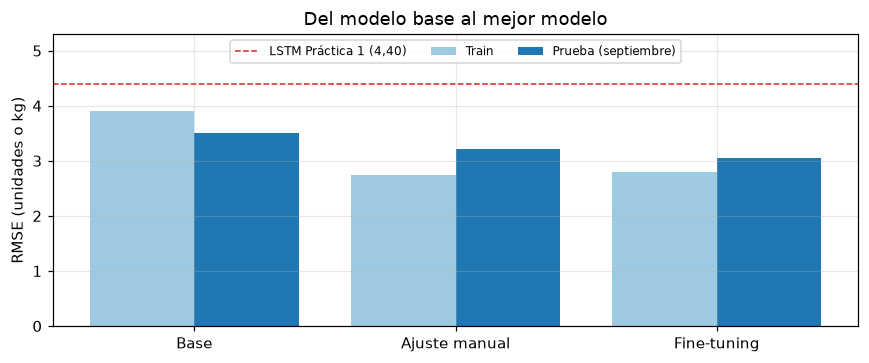

In [14]:
modelos_finales = {
    "Base (lineal, por defecto)": clone(modelos_etapa["base"]).fit(X_busqueda, y_busqueda),
    f"Ajuste manual (RBF, C={MEJOR_C:g})": final,
    "Fine-tuning ({svr__kernel}, C={svr__C}, γ={svr__gamma}, ε={svr__epsilon})".format(**seleccionada.best_params_): mejor_modelo,
}
filas = []
for nombre, modelo in modelos_finales.items():
    p = np.clip(modelo.predict(X_te), 0, None)
    filas.append({"modelo": nombre, "RMSE train": rmse(y_busqueda, modelo.predict(X_busqueda)),
                  "RMSE prueba": rmse(y_te, p), "MAE prueba": mean_absolute_error(y_te, p)})
etapas_tabla = pd.DataFrame(filas).set_index("modelo")
display(etapas_tabla.round(2))

etiquetas = ["Base", "Ajuste manual", "Fine-tuning"]
pos = np.arange(3)
plt.figure(figsize=(8, 3.4))
plt.bar(pos - 0.2, etapas_tabla["RMSE train"], 0.4, label="Train", color="#9ecae1")
plt.bar(pos + 0.2, etapas_tabla["RMSE prueba"], 0.4, label="Prueba (septiembre)", color="#1f77b4")
plt.axhline(4.40, color="#d62728", ls="--", lw=1, label="LSTM Práctica 1 (4,40)")
plt.xticks(pos, etiquetas); plt.ylabel("RMSE (unidades o kg)"); plt.ylim(0, 5.3)
plt.legend(fontsize=8, ncol=3, loc="upper center")
plt.title("Del modelo base al mejor modelo")
plt.tight_layout(); plt.savefig(FIG / "06_base_vs_mejor.png", dpi=200); plt.show()

<div id="ejemplos-cliente" style="color:#37475a; background-color:#fff; border-bottom:3px solid #42A5F5; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h3 style="color:inherit;">2.7 Ejemplos para el cliente</h3></div>

Demanda real de septiembre frente a la predicha por el modelo base y por el mejor modelo, y lo que se habría pedido en el mes con cada uno.

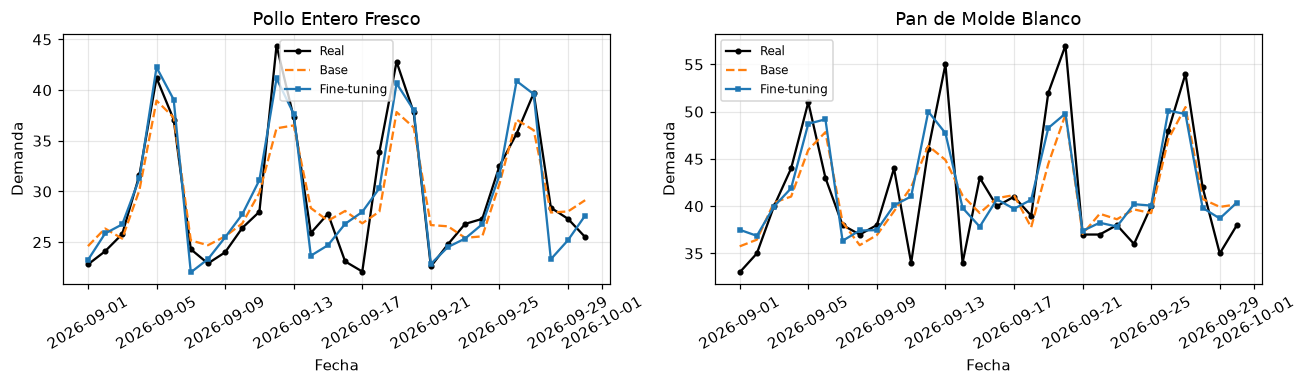

,Demanda real,Pedido con base,Pedido con fine-tuning,Desfase base,Desfase fine-tuning
nombre,,,,,
Aceite Vegetal Palma 1L,716.0,734.0,727.6,18.0,11.6
Arroz Flor Blanco 1kg,1414.0,1394.8,1405.1,-19.2,-8.9
Detergente Multiuso 1kg,422.0,442.4,438.7,20.4,16.7
Huevos Blancos Empaque 12u,1052.0,1048.4,1062.9,-3.6,10.9
Leche Entera Tetrapack 1L,1582.0,1571.2,1598.6,-10.8,16.6
Lomo Fino de Res,292.8,318.6,299.9,25.8,7.1
Manzana Royal Gala,612.7,620.3,611.6,7.6,-1.1
Pan de Molde Blanco,1249.0,1237.9,1253.6,-11.1,4.6
Pollo Entero Fresco,893.9,893.4,896.9,-0.5,3.0


Desfase absoluto total del mes: base 127.5 | fine-tuning 89.3


In [15]:
ejemplo = datos.loc[te, ["product_id", "nombre", "fecha_venta", "cantidad_vendida"]].copy()
ejemplo["base"] = np.clip(modelos_finales["Base (lineal, por defecto)"].predict(X_te), 0, None)
ejemplo["mejor"] = np.clip(mejor_modelo.predict(X_te), 0, None)

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, cod in zip(ejes, ["114674", "103665"]):
    g = ejemplo[ejemplo["product_id"] == cod]
    ax.plot(g["fecha_venta"], g["cantidad_vendida"], "o-", ms=3, color="black", label="Real")
    ax.plot(g["fecha_venta"], g["base"], "--", color="#ff7f0e", label="Base")
    ax.plot(g["fecha_venta"], g["mejor"], "s-", ms=3, color="#1f77b4", label="Fine-tuning")
    ax.set(title=g["nombre"].iloc[0], xlabel="Fecha", ylabel="Demanda"); ax.legend(fontsize=8)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG / "07_cliente_real_vs_pred.png", dpi=200); plt.show()

pedido = ejemplo.groupby("nombre")[["cantidad_vendida", "base", "mejor"]].sum().round(1)
pedido.columns = ["Demanda real", "Pedido con base", "Pedido con fine-tuning"]
pedido["Desfase base"] = (pedido["Pedido con base"] - pedido["Demanda real"]).round(1)
pedido["Desfase fine-tuning"] = (pedido["Pedido con fine-tuning"] - pedido["Demanda real"]).round(1)
display(pedido)
print(f"Desfase absoluto total del mes: base {pedido['Desfase base'].abs().sum():.1f} | fine-tuning {pedido['Desfase fine-tuning'].abs().sum():.1f}")

<div id="conclusiones" style="color:#37475a; background-color:#fff; border-bottom:7px solid orange; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h2 style="color:inherit;">Conclusiones</h2></div>

1. **Modelo base:** el SVR lineal con valores por defecto obtiene RMSE 3,90 en train y 3,50 en prueba. El error es alto incluso en train (subajuste): una recta no alcanza los picos de fin de semana y feriado (figura 07).
2. **Ajuste manual:** pasar a kernel RBF con C = 10 baja el error de prueba a 3,21. En la Parte 1, C = 1000 mostró sobreajuste (train 1,98 y validación 4,45).
3. **Fine-tuning con MLflow:** GridSearch (42 combinaciones) encontró el mejor modelo: RBF, C = 100, γ = 0,01 y ε = 1, con RMSE 3,29 en validación y **RMSE 3,05 / MAE 2,21 en prueba**. RandomSearch (20 combinaciones) tardó menos de la mitad, pero se quedó en 3,51 de validación.
4. **Sobreajuste:** el mejor modelo tiene la menor brecha entre train y prueba (2,80 frente a 3,05), así que generaliza mejor que el ajuste manual (2,73 frente a 3,21).
5. **Para el cliente:** en septiembre, el desfase total entre lo que se habría pedido y la demanda real baja de 127,5 (base) a 89,3 unidades/kg con el fine-tuning, un 30 % menos.
6. **SVM frente a la red recurrente (LSTM):** la SVR ajustada tiene RMSE 3,05 frente a 4,40 de la LSTM de la Práctica 1 (31 % menos error) y MAE 2,21 frente a 3,10. Con pocos datos (3.580 filas) y variables de calendario y rezagos, la SVR aprende mejor y entrena en segundos. La LSTM aprende la secuencia por sí sola, pero necesita más datos, épocas y ajuste; la SVR, en cambio, depende de que el tiempo entre como variables (timestamp y rezagos).
7. **Limitaciones:** los datos son sintéticos y la predicción es a un día; los tiempos de búsqueda cambian según el equipo.

<div id="referencias" style="color:#37475a; background-color:#fff; border-bottom:7px solid orange; width:100%; margin-top:24px; margin-bottom:15px; padding-bottom:2px;"><h2 style="color:inherit;">Referencias</h2></div>

- Bishop, C. M. (2006). *Pattern recognition and machine learning*. Springer.
- Schölkopf, B., & Smola, A. J. (2002). *Learning with kernels: Support vector machines, regularization, optimization, and beyond*. MIT Press.
- Raschka, S., & Mirjalili, V. (2017). *Python machine learning* (2.ª ed.). Packt Publishing.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Zaharia, M., Chen, A., Davidson, A., Ghodsi, A., Hong, S. A., Konwinski, A., ... Zumar, C. (2018). Accelerating the machine learning lifecycle with MLflow. *IEEE Data Engineering Bulletin, 41*(4), 39–45.